(mitochondrial_lineage_tracing)=

# Mitochondrial lineage tracing

Cells that share a somatic mutation in their mitochondrial DNA share an ancestor. A cell holds many copies of its 16,569-base mitochondrial genome, and a mutation in one copy can drift until it fills a large share of them, the mutation's heteroplasmy, which the cell's descendants inherit. Mitochondrial mutations therefore trace clones in human tissue, which no engineered barcode marks [@Ludwig_2019]. mtscATAC-seq reads each cell's mitochondrial genome together with its chromatin accessibility [@Lareau_2020].

This page analyzes the colorectal adenocarcinoma that @Lareau_2020 profiled with mtscATAC-seq, a resected tumor with its epithelial cells and the immune cells that infiltrated it. It names the cell types from the peak counts, imports each cell's reads of each base at each mitochondrial position, selects the variants that differ between cells, calls the clones they mark, and compares the cell types by the clones they share.

## Download the data

[Zenodo record 3977808](https://zenodo.org/records/3977808) holds processed data of the paper under CC BY 4.0. For the colorectal cancer sample, download two outputs of Cell Ranger ATAC, the counts of fragments in peaks for the barcodes it called cells and its metrics for every barcode, and the output of mgatk, the paper's tool for mitochondrial variants: each cell's reads of A, C, G and T at each mitochondrial position in four files, each cell's mean depth, and the reference sequence. The eight files take 211 MB, and each is checked against the MD5 checksum that Zenodo lists for it.

The example uses a temporary directory. Use a project directory instead if you want to keep the downloaded files and the store after closing the notebook.

In [1]:
# Download and verify the published files.
import hashlib
import shutil
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import urlopen

# Read Cell Ranger's per-barcode metrics and summarize results in tables.
import pandas as pd

# Analyze the data.
import cytearc

# Keep routine logs and progress bars out of the results.
cytearc.configure_output(level="WARNING", progress=False)

# Keep this example's downloads and store together.
work = TemporaryDirectory()
output_dir = Path(work.name)

Started: 2026-11-06T15:52:16.176591Z | Wall time: 0.744 s

In [2]:
# Pin the eight files to the checksums that Zenodo lists, so that a changed
# download cannot alter the example silently.
record = "https://zenodo.org/records/3977808/files/CRC_v12-mtMask_mgatk."
cell_ranger_files = {
    "filtered_peak_bc_matrix.h5": "650f21439dd46d4941b454ccd241f316",
    "singlecell.csv": "bda506977f7d219335bcd1c198e79a79",
}
mgatk_files = {
    "A.txt.gz": "584be3fd63b3d4c4f5135bf3e7e6adad",
    "C.txt.gz": "5bf7ace3e682df978f5d9b2206657663",
    "G.txt.gz": "aae5a90a1e1071862407bd37d932f1df",
    "T.txt.gz": "44ea9fb15dd0676828c1a1da29f37daf",
    "depthTable.txt": "de7672365bfdb069776b469b3fee280a",
    "chrM_refAllele.txt": "07253834698fa1171e55971b715511a8",
}

# Keep mgatk's six files in a folder of their own, which the import reads.
mgatk_dir = output_dir / "mgatk"
mgatk_dir.mkdir()
paths = {}
for folder, files in ((output_dir, cell_ranger_files), (mgatk_dir, mgatk_files)):
    for name, expected_digest in files.items():
        path = folder / f"CRC_v12-mtMask_mgatk.{name}"

        # Copy the response in blocks without holding the file in memory.
        with urlopen(record + name, timeout=60) as response, path.open("wb") as target:
            shutil.copyfileobj(response, target)

        # Reject a file whose contents differ from the published one.
        with path.open("rb") as source:
            actual_digest = hashlib.file_digest(source, "md5").hexdigest()
        if actual_digest != expected_digest:
            raise ValueError(f"Checksum mismatch for {path.name}")
        paths[name] = path

# Show the size of each completed download.
pd.Series(
    {name: path.stat().st_size / 1_000_000 for name, path in paths.items()},
    name="Downloaded MB",
).round(2)

filtered_peak_bc_matrix.h5    18.81
singlecell.csv                23.20
A.txt.gz                      51.36
C.txt.gz                      51.74
G.txt.gz                      24.23
T.txt.gz                      41.84
depthTable.txt                 0.09
chrM_refAllele.txt             0.12
Name: Downloaded MB, dtype: float64

Started: 2026-11-06T15:52:16.924720Z | Wall time: 171.090 s

## Filter the cells as the paper did

`CrToZarr` writes the peak counts into a store with an `ATAC` assay, one row per barcode that Cell Ranger called a cell. The paper kept the cells with at least 1,000 unique nuclear fragments, at least 40% of them in DNase hypersensitive sites, regions open in many cell types, and a mitochondrial depth of at least 10 reads per position [@Lareau_2020]. Cell Ranger's metrics hold the first two: `passed_filters` counts each barcode's fragments that remain once duplicate, chimeric, unmapped, low-quality and mitochondrial reads are set aside, and `DNase_sensitive_region_fragments` those of them in DNase hypersensitive sites. The depth filter follows once the mitochondrial counts are imported.

In [3]:
# Write the peak counts into a new store and open it.
store_path = output_dir / "crc.zarr"
cytearc.CrToZarr(
    cytearc.CrH5Reader(str(paths["filtered_peak_bc_matrix.h5"])),
    zarr_loc=str(store_path),
).dump()
ds = cytearc.DataStore(str(store_path), default_assay="ATAC")

# Read each cell's unique nuclear fragments, and the share of them in DNase
# hypersensitive sites, from Cell Ranger's per-barcode metrics.
cell_ids = ds.cells.fetch_all("ids")
metrics = pd.read_csv(paths["singlecell.csv"], index_col="barcode").reindex(cell_ids)
nuclear_fragments = metrics["passed_filters"]
dnase_share = metrics["DNase_sensitive_region_fragments"] / nuclear_fragments

# Mark the cells that pass both bounds, and freeze them as a cell selection.
passes_qc = (nuclear_fragments >= 1000) & (dnase_share >= 0.4)
ds.cells.insert("passes_qc", passes_qc.to_numpy())
qc_cells = ds.snapshot_cell_selection("passes_qc")

# Count the cells that each bound keeps.
pd.Series(
    {
        "Called by Cell Ranger": len(metrics),
        "At least 1,000 nuclear fragments": int((nuclear_fragments >= 1000).sum()),
        "At least 40% of them in DNase sites": int((dnase_share >= 0.4).sum()),
        "Both": int(passes_qc.sum()),
    },
    name="Cells",
)

Called by Cell Ranger                  3535
At least 1,000 nuclear fragments       2004
At least 40% of them in DNase sites    3533
Both                                   2003
Name: Cells, dtype: int64

Started: 2026-11-06T15:55:08.018932Z | Wall time: 9.731 s

2,003 of the 3,535 cells pass, nearly all of the others for too few fragments.

## Name the cell types

The ATAC recipe reduces the peak counts of these cells with latent semantic indexing (LSI), then builds, embeds and clusters their neighbor graph. This page uses the settings of the prepared analysis in [](scatac_seq.ipynb): 50 LSI components of the 25,000 most prevalent peaks, and 21 neighbors. To name the clusters, sum the accessibility of the peaks that overlap each gene into a `GeneScores` assay, from gene intervals on the reference of the peaks, hg19 (GRCh37). Two warnings are expected: the peaks leave out the mitochondrial genome, and many genes overlap no peak.

In [4]:
# Reduce the peak counts of these cells with LSI, then build, embed and
# cluster their neighbor graph.
run = ds.pipeline.atac(
    label="atac",
    cells=qc_cells,
    prevalent_peaks={"top_n": 25000},
    lsi={"dims": 50, "skip_first": True},
    neighbors={"k": 21},
    markers=False,
)
clusters = run["clusters"]

# Download gene intervals for the reference genome of the peaks.
annotations = cytearc.datasets.connect("cytearc_docs").download_dataset(
    "annotations", destination=output_dir
)

# Sum the accessibility of the peaks that overlap each gene.
ds.add_melded_assay(
    from_assay="ATAC",
    external_bed_fn=str(annotations / "human_GRCh37_gencode_v38_gene_body.bed.gz"),
    renormalization=False,
    assay_label="GeneScores",
    assay_type="RNA",
)

Started: 2026-11-06T15:55:17.755065Z | Wall time: 174.873 s

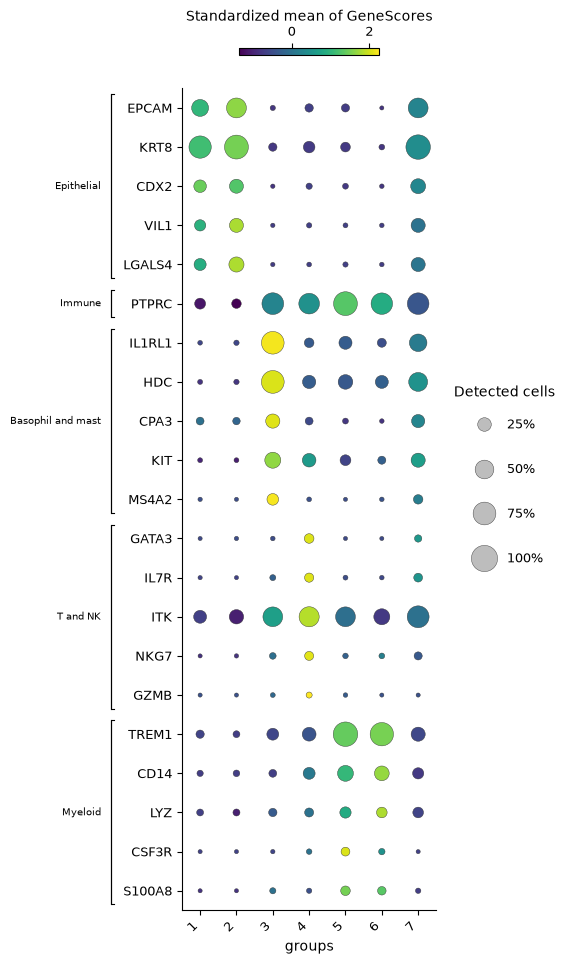

Started: 2026-11-06T15:58:12.631327Z | Wall time: 2.186 s

In [5]:
# Compare the gene scores of lineage markers across the clusters.
marker_panel = {
    "Epithelial": ["EPCAM", "KRT8", "CDX2", "VIL1", "LGALS4"],
    "Immune": ["PTPRC"],
    "Basophil and mast": ["IL1RL1", "HDC", "CPA3", "KIT", "MS4A2"],
    "T and NK": ["GATA3", "IL7R", "ITK", "NKG7", "GZMB"],
    "Myeloid": ["TREM1", "CD14", "LYZ", "CSF3R", "S100A8"],
}
ds.plots.dotplot(
    features=marker_panel,
    groups=clusters,
    from_assay="GeneScores",
    standardize="feature",
)

Clusters 1 and 2 are epithelial, accessible at EPCAM, the keratin gene KRT8, the intestinal transcription factor CDX2, VIL1 and LGALS4. PTPRC, the gene of the immune cell marker CD45, is accessible in clusters 3 to 6: in cluster 3 with the genes of basophils and mast cells, cells that the paper calls basophil-like, in cluster 4 with genes of T and NK cells, and in clusters 5 and 6 with genes of myeloid cells. Cluster 7 is accessible at the epithelial genes and at those of the basophil-like cells.

In [6]:
# Count each cluster's cells and the median of their counts in peaks.
cluster_labels = ds.artifacts.load_values(clusters).to_pandas().rename("cluster")
peak_counts = pd.Series(ds.cells.fetch_all("ATAC_nCounts"), index=cell_ids)
pd.DataFrame(
    {
        "Cells": cluster_labels.value_counts().sort_index(),
        "Median counts in peaks": peak_counts.groupby(cluster_labels).median(),
    }
)

,Cells,Median counts in peaks
cluster,,
1,646,4360.0
2,394,6871.5
3,316,12488.0
4,238,8902.0
5,187,15102.0
6,167,8794.0
7,55,19307.0


Started: 2026-11-06T15:58:14.821326Z | Wall time: 0.056 s

Cluster 7 also holds the most counts in peaks, 19,307 per cell at the median against 4,360 to 15,102 in the others, as droplets with two cells do: its cells are doublets of an epithelial and a basophil-like cell.

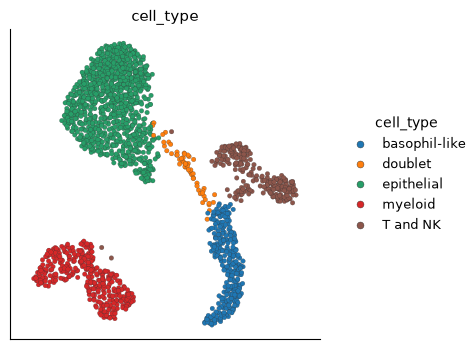

Started: 2026-11-06T15:58:14.880540Z | Wall time: 0.336 s

In [7]:
# Name each cluster by its cell type, in the order the tables list them.
cell_type_by_cluster = {
    1: "epithelial",
    2: "epithelial",
    3: "basophil-like",
    4: "T and NK",
    5: "myeloid",
    6: "myeloid",
    7: "doublet",
}
type_order = pd.CategoricalDtype(list(dict.fromkeys(cell_type_by_cluster.values())))
cell_types = cluster_labels.map(cell_type_by_cluster).astype(type_order)
cell_types = cell_types.rename("cell type")

# Save each cell's type as a cell column, and name the cells that quality
# control removed "not analyzed".
ds.cells.insert(
    "cell_type",
    cell_types.astype(str).reindex(cell_ids, fill_value="not analyzed"),
    overwrite=True,
)

# Locate the cell types on the UMAP.
ds.plots.embedding(layout=run["umap"], color_by="cell_type")

## Import the mitochondrial counts

mgatk counts each cell's reads of each base at each of the 16,569 positions of the mitochondrial genome, on each strand of DNA. `variants.import_counts` reads its folder and joins each barcode to the cell with the same ID. Import the counts for the cells that the ATAC recipe analyzed, so that the variants and clones share the cells of its UMAP. A cell's depth at a position is its reads there; where a cell has no read, its allele frequency is undefined rather than 0.

In [8]:
# Import mgatk's counts for the cells of the ATAC analysis.
counts = ds.variants.import_counts(
    mgatk_dir, cell_selection=run["analysis_cell_selection"]
)

# Check how mgatk's barcodes joined the store's cells.
joined = ds.artifacts.inspect(counts).diagnostics
pd.Series(
    {
        "Barcodes in mgatk's files": joined["fileBarcodes"],
        "Of cells outside the analysis": joined["unselectedBarcodes"],
        "Matching no cell of the store": joined["unmatchedBarcodes"],
        "Analyzed cells with counts": joined["listedCells"],
    },
    name="Barcodes",
)

Barcodes in mgatk's files        3511
Of cells outside the analysis    1508
Matching no cell of the store       0
Analyzed cells with counts       2003
Name: Barcodes, dtype: int64

Started: 2026-11-06T15:58:15.219764Z | Wall time: 14.580 s

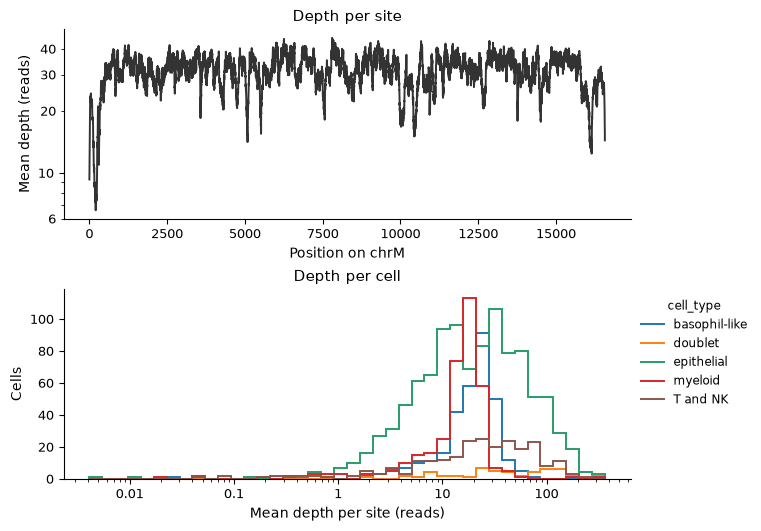

Started: 2026-11-06T15:58:29.802488Z | Wall time: 0.894 s

In [9]:
# Draw the mean depth at each position, and each cell's mean depth by cell type.
ds.plots.variant_depth(counts, group_by="cell_type")

In [10]:
# Count the cells of each type, their median depth, and those with a mean
# depth of at least 10 reads.
mean_depth = ds.artifacts.load_values(counts).to_pandas()
depth_by_type = mean_depth.groupby(cell_types.reindex(mean_depth.index), observed=True)
pd.DataFrame(
    {
        "Cells": depth_by_type.size(),
        "Median depth": depth_by_type.median().round(1),
        "Depth of 10 or more": depth_by_type.apply(lambda depth: (depth >= 10).sum()),
    }
)

,Cells,Median depth,Depth of 10 or more
cell type,,,
epithelial,1040,19.9,727
basophil-like,316,21.1,271
T and NK,238,24.2,181
myeloid,354,16.3,280
doublet,55,45.3,46


Started: 2026-11-06T15:58:30.700096Z | Wall time: 0.049 s

Most cells reach the paper's bound of 10 reads per position, 727 of the 1,040 epithelial cells and 732 of the 908 immune cells, and the doublets, with the mitochondria of two cells, read the most. Keep the cells that reach the bound, the deep cells, and the singlets among them for the variant analysis.

In [11]:
# Keep the cells with a mean depth of at least 10 reads, and the singlets
# among them.
deep_cells = ds.select_cells(counts, low=10, keep_bounds=True)
deep_singlets = ds.select_cells(
    clusters, include=[1, 2, 3, 4, 5, 6], cell_selection=deep_cells
)

Started: 2026-11-06T15:58:30.752252Z | Wall time: 0.126 s

## Find the informative variants

A variant is a base that differs from the reference at a position, such as `16147C>T`, a T where the reference holds C at position 16,147. Inherited variants are carried by every cell, and informative ones differ between cells. `variants.informative` scores each variant with the statistics of mgatk [@Lareau_2020]: the variance-to-mean ratio (VMR) of its allele frequency across cells, high when some cells carry the variant and others do not; its strand correlation, the agreement of its reads on the two strands of DNA across cells, since sequencing errors tend to appear on one strand; and the cells that detect it confidently, reading it at least twice on each strand. `preset="atac"` applies the paper's thresholds: at least 5 cells that detect the variant confidently, a strand correlation of at least 0.65 and a VMR above 0.01. The masks leave out positions where nuclear copies of mitochondrial DNA or sequencing artifacts mimic variants.

In [12]:
# Score every variant that the deep singlets show, and select the informative
# ones by the thresholds for mtscATAC-seq.
informative = ds.variants.informative(
    counts,
    cell_selection=deep_singlets,
    preset="atac",
    mask=["numt", "artifact_prone"],
)

# List the informative variants by their pooled allele frequency.
variants = ds.variants.load_informative(informative).variants
selected = variants[variants["informative"]].sort_values("mean", ascending=False)
selected[["mean", "vmr", "strand_correlation", "n_cells_conf_detected"]].round(3)

,mean,vmr,strand_correlation,n_cells_conf_detected
variant,,,,
chrM:16147C>T,0.603,0.402,0.913,621
chrM:12889G>A,0.021,0.141,0.875,88
chrM:9728C>T,0.013,0.352,0.922,30
chrM:1227G>A,0.008,0.222,0.969,25
chrM:16093T>C,0.008,0.738,0.994,8
chrM:2285T>C,0.005,0.956,0.926,9
chrM:824T>C,0.005,0.875,0.968,10
chrM:9804G>A,0.003,0.978,0.979,9
chrM:6081G>A,0.003,0.255,0.820,8


Started: 2026-11-06T15:58:30.881931Z | Wall time: 2.485 s

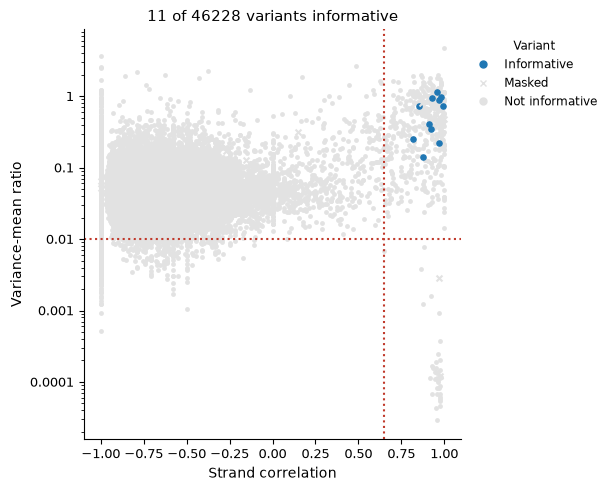

Started: 2026-11-06T15:58:33.369598Z | Wall time: 0.697 s

In [13]:
# Draw each variant's VMR against its strand correlation.
ds.plots.variant_statistics(informative)

Eleven variants pass. 16147C>T makes up 60% of the reads at its position, and each of the other ten 0.1 to 2.1% at its own: variants that only some cells carry. The grey points at the lower right of the plot are variants that every cell carries, inherited differences from the reference.

## See which cells carry each variant

A cell's allele frequency of a variant, its reads of the variant over its depth at the position, estimates the variant's heteroplasmy in that cell. Compute the frequencies of the informative variants in every deep cell, the doublets included, color the UMAP by them, and count the cells of each type that detect each variant confidently.

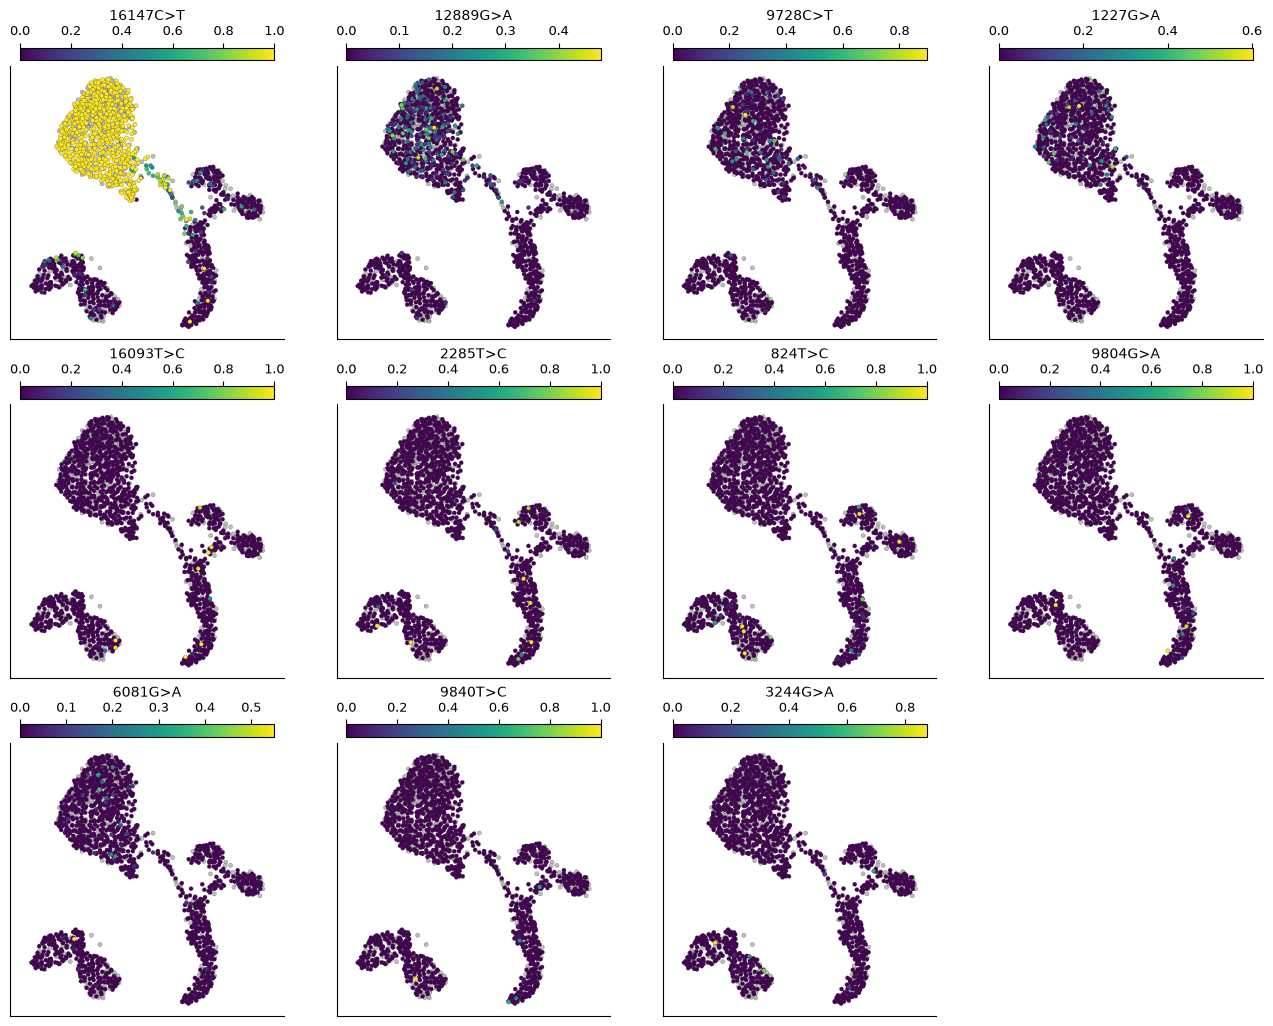

Started: 2026-11-06T15:58:34.069669Z | Wall time: 3.575 s

In [14]:
# Read the counts at the informative variants' positions in the deep cells.
loaded = ds.variants.load_counts(
    counts, sites=selected["position"].tolist(), cell_selection=deep_cells
)

# Divide each cell's reads of each variant by its depth at the position. A
# covered cell without a read of the variant has frequency 0, and a cell that
# was not covered has none.
frequencies = {}
for label, variant in selected.iterrows():
    depth = loaded.depth[loaded.depth["site"] == variant["site"]].set_index("ids")
    reads = loaded.counts[
        (loaded.counts["site"] == variant["site"])
        & (loaded.counts["allele"] == variant["alternative"])
    ].set_index("ids")
    name = label.removeprefix("chrM:")
    frequencies[name] = (
        reads["count"].reindex(depth.index, fill_value=0) / depth["depth"]
    )
frequencies = pd.DataFrame(frequencies)

# Save each frequency as a cell column, and color the UMAP by them.
for name in frequencies:
    ds.cells.insert(name, frequencies[name].reindex(cell_ids), overwrite=True)
ds.plots.embedding(
    layout=run["umap"], color_by=list(frequencies), n_columns=4, sort_values=True
)

In [15]:
# Count the deep cells of each type that read each variant at least twice on
# each strand.
confident = {}
for label, variant in selected.iterrows():
    reads = loaded.counts[
        (loaded.counts["site"] == variant["site"])
        & (loaded.counts["allele"] == variant["alternative"])
    ]
    carriers = reads.loc[(reads["forward"] >= 2) & (reads["reverse"] >= 2), "ids"]
    confident[label.removeprefix("chrM:")] = (
        cell_types.reindex(carriers).value_counts(sort=False)
    )
pd.DataFrame(confident).T

cell type,epithelial,basophil-like,T and NK,myeloid,doublet
16147C>T,600,5,9,7,38
12889G>A,85,0,2,1,11
9728C>T,29,0,0,1,3
1227G>A,25,0,0,0,1
16093T>C,0,3,3,2,0
2285T>C,0,5,2,2,1
824T>C,0,3,3,4,0
9804G>A,0,6,2,1,0
6081G>A,7,0,0,1,2
9840T>C,0,3,1,1,0


Started: 2026-11-06T15:58:37.647794Z | Wall time: 0.055 s

16147C>T fills the epithelial cells, and the doublets on the bridge carry it at intermediate frequencies, as droplets that mix the mitochondria of an epithelial and a basophil-like cell would. Four variants, 12889G>A, 9728C>T, 1227G>A and 6081G>A, mark parts of the epithelial cells, subclones of the tumor. Each of the six others is detected confidently in immune cells of all three types and in no epithelial cell, so it most likely arose in a progenitor of these lineages, such as a hematopoietic stem cell.

## Call clones

`variants.frequency_clones` groups the cells whose variants agree, as Signac's `FindClonotypes` does [@Stuart_2021]: it builds a graph of each cell's neighborhood of 10 cells by the similarity of their allele frequencies, and partitions the graph with the Leiden algorithm [@Traag_2019]. Cells that show none of the informative variants get no clone. At the default resolution of 1, the Leiden algorithm splits the cells that carry 16147C>T alone into two clones; a resolution of 0.75 keeps them together.

In [16]:
# Call clones from the informative variants of the deep singlets.
clones = ds.variants.frequency_clones(informative, resolution=0.75)

# Count the cells that the clones hold and those they leave out.
called = ds.artifacts.inspect(clones).diagnostics
pd.Series(
    {
        "Deep singlets": called["cellsScored"],
        "With a clone": called["cellsWithClone"],
        "Showing no informative variant": called["cellsWithoutAlternative"],
    },
    name="Cells",
)

Deep singlets                     1459
With a clone                       895
Showing no informative variant     564
Name: Cells, dtype: int64

Started: 2026-11-06T15:58:37.705585Z | Wall time: 4.027 s

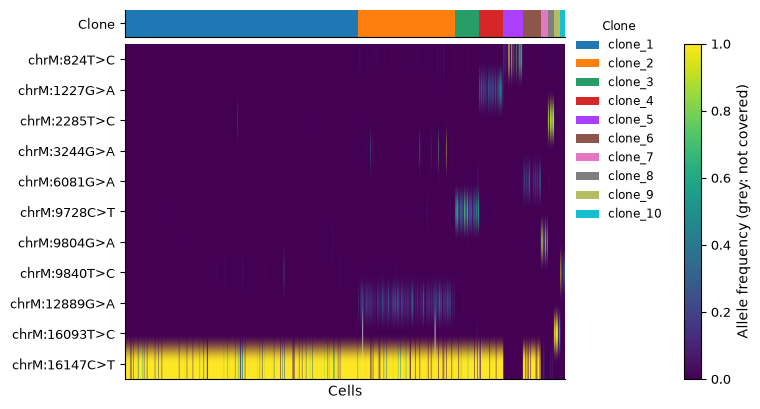

Started: 2026-11-06T15:58:41.735243Z | Wall time: 1.630 s

In [17]:
# Draw each cell's allele frequencies, ordered by clone.
ds.plots.allele_frequencies(informative, clones=clones)

In [18]:
# Name the variants that each clone's cells carry at a mean frequency of at
# least 10%, and count the clone's cells of each type.
clone_cells = ds.clones.load_clones(clones).cells
mean_frequencies = frequencies.groupby(clone_cells["clone"], observed=True).mean()
composition = pd.crosstab(clone_cells["clone"], cell_types.reindex(clone_cells.index))
composition.insert(
    0,
    "variants",
    mean_frequencies.apply(lambda clone: ", ".join(clone.index[clone >= 0.1]), axis=1),
)
composition

cell type,variants,epithelial,basophil-like,T and NK,myeloid
clone,,,,,
clone_1,16147C>T,430,12,12,20
clone_2,"16147C>T, 12889G>A",174,5,8,10
clone_3,"16147C>T, 9728C>T",45,0,1,3
clone_4,"16147C>T, 1227G>A",45,0,3,1
clone_5,824T>C,0,14,13,13
clone_6,"16147C>T, 6081G>A",29,2,1,4
clone_7,9804G>A,0,8,2,4
clone_8,2285T>C,0,6,3,4
clone_9,16093T>C,0,5,5,3


Started: 2026-11-06T15:58:43.367427Z | Wall time: 0.063 s

Of the 1,459 deep singlets, 895 get a clone. Five clones carry 16147C>T and hold the 723 epithelial cells with a clone, four of them as subclones with a second variant, and the other five each carry one immune variant and hold immune cells of all three types. The tumor clones also hold 82 immune cells, most of them without a confident read of the tumor's variants: the clones compare the pattern of each cell's frequencies, not the reads behind them, so a stray read can place a cell. The few carriers of 3244G>A, too few to fill a neighborhood of 10 cells, join the second clone.

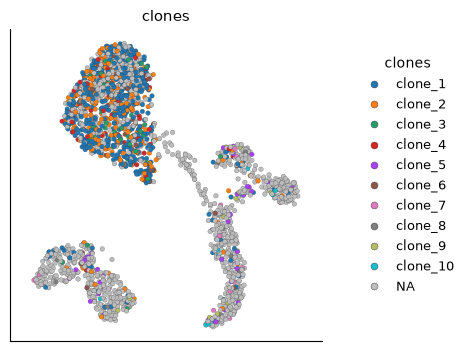

Started: 2026-11-06T15:58:43.432583Z | Wall time: 0.278 s

In [19]:
# Locate the clones on the UMAP.
ds.plots.embedding(layout=run["umap"], color_by=clones)

The subclones mix across the epithelial cells on the UMAP, so their chromatin differs less than that of the cell types.

## Compare the cell types by their clones

`clones.coupling` measures how much each pair of cell types shares clones: the cosine similarity of their shares of each clone, as a z-score against random assignments of the same cells to the types.

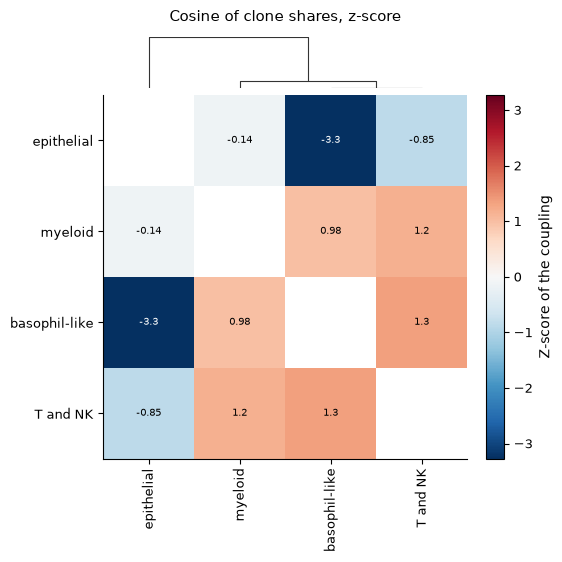

Started: 2026-11-06T15:58:43.712728Z | Wall time: 3.790 s

In [20]:
# Measure the coupling of each pair of cell types through their clones.
coupling = ds.clones.coupling(clones, group_by="cell_type")
ds.plots.clone_coupling(coupling, value="z_score")

The immune cell types couple with one another, as the clones of their shared variants make them, and the epithelial cells couple with none of them, least with the basophil-like cells. The immune cells that the tumor clones hold bring the epithelial cells near chance with the myeloid and the T and NK cells.

## Next steps

- With several samples or donors, pass `within="donor"` to `variants.frequency_clones`, so that no clone joins the cells of two people.
- For MAESTER and other RNA libraries, select variants with `preset="rna"`, which tests depth and base quality instead of strands.
- Every clone summary, from diversity to fate bias, takes these clones, as the [clones API reference](/api/clones.html) describes. The [variants API reference](/api/variants.html) covers the other formats that `variants.import_counts` reads and the genotypes of targeted sites, from GoT, GIFT, Tapestri and DAb-seq.